In [13]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import r2_score, mean_squared_error, accuracy_score, roc_auc_score

In [2]:
# Load the built-in diabetes progression dataset with a continuous target
uci = load_diabetes(as_frame=True)
uci_data = uci.data.copy()
uci_data["Target"] = uci.target

print("Continuous-target diabetes dataset shape:", uci_data.shape)
uci_data.head()

Continuous-target diabetes dataset shape: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [3]:
# Load the Pima Indians diabetes dataset
pima_data = pd.read_csv("diabetes.csv")
print("Pima dataset shape:", pima_data.shape)
pima_data.head()

Pima dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
# Prepare the Pima dataset by treating impossible zero measurements as missing
pima_data = pima_data.copy()
zero_missing_columns = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
for column in zero_missing_columns:
    if column in pima_data.columns:
        pima_data[column] = pima_data[column].replace(0, np.nan)

print("Missing values in Pima dataset:")
print(pima_data.isnull().sum())

Missing values in Pima dataset:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [5]:
# Calculate univariate statistics for numerical columns
def univariate_analysis(frame):
    numeric = frame.select_dtypes(include=np.number)
    summary = pd.DataFrame({
        "Frequency": numeric.count(),
        "Missing": numeric.isnull().sum(),
        "Unique Values": numeric.nunique(),
        "Mean": numeric.mean(),
        "Median": numeric.median(),
        "Mode": numeric.mode().iloc[0],
        "Variance": numeric.var(),
        "Standard Deviation": numeric.std(),
        "Skewness": numeric.skew(),
        "Kurtosis": numeric.kurtosis()
    })
    return summary.round(3)

print("Continuous-target Diabetes Univariate Analysis")
display(univariate_analysis(uci_data))

print("Pima Indians Diabetes Univariate Analysis")
display(univariate_analysis(pima_data))

Continuous-target Diabetes Univariate Analysis


,Frequency,Missing,Unique Values,Mean,Median,Mode,Variance,Standard Deviation,Skewness,Kurtosis
age,442,0,58,-0.000,0.005,0.016,0.002,0.048,-0.231,-0.671
sex,442,0,2,0.000,-0.045,-0.045,0.002,0.048,0.127,-1.993
bmi,442,0,163,-0.000,-0.007,-0.031,0.002,0.048,0.598,0.095
bp,442,0,100,-0.000,-0.006,-0.040,0.002,0.048,0.291,-0.533
s1,442,0,141,-0.000,-0.004,-0.037,0.002,0.048,0.378,0.233
s2,442,0,302,0.000,-0.004,-0.001,0.002,0.048,0.437,0.601
s3,442,0,63,-0.000,-0.007,-0.014,0.002,0.048,0.799,0.982
s4,442,0,66,-0.000,-0.003,-0.039,0.002,0.048,0.735,0.444
s5,442,0,184,0.000,-0.002,-0.018,0.002,0.048,0.292,-0.134
s6,442,0,56,0.000,-0.001,0.003,0.002,0.048,0.208,0.237


Pima Indians Diabetes Univariate Analysis


,Frequency,Missing,Unique Values,Mean,Median,Mode,Variance,Standard Deviation,Skewness,Kurtosis
Pregnancies,768,0,17,3.845,3.000,1.000,11.354,3.370,0.902,0.159
Glucose,763,5,135,121.687,117.000,99.000,932.425,30.536,0.531,-0.277
BloodPressure,733,35,46,72.405,72.000,70.000,153.318,12.382,0.134,0.911
SkinThickness,541,227,50,29.153,29.000,32.000,109.767,10.477,0.691,2.935
Insulin,394,374,185,155.548,125.000,105.000,14107.704,118.776,2.166,6.371
BMI,757,11,247,32.457,32.300,32.000,47.955,6.925,0.594,0.863
DiabetesPedigreeFunction,768,0,517,0.472,0.372,0.254,0.110,0.331,1.920,5.595
Age,768,0,52,33.241,29.000,22.000,138.303,11.760,1.130,0.643
Outcome,768,0,2,0.349,0.000,0.000,0.227,0.477,0.635,-1.601


In [6]:
# Display target frequency counts for both datasets
print("Continuous-target diabetes summary:")
print(uci_data["Target"].describe())

print("\nPima outcome frequency:")
print(pima_data["Outcome"].value_counts().sort_index())

# Create a high/low progression label for logistic regression on the continuous UCI target
uci_median_target = uci_data["Target"].median()
uci_data["High_Progression"] = (uci_data["Target"] > uci_median_target).astype(int)
print("\nUCI high/low progression frequency:")
print(uci_data["High_Progression"].value_counts().sort_index())

Continuous-target diabetes summary:
count    442.000000
mean     152.133484
std       77.093005
min       25.000000
25%       87.000000
50%      140.500000
75%      211.500000
max      346.000000
Name: Target, dtype: float64

Pima outcome frequency:
Outcome
0    500
1    268
Name: count, dtype: int64

UCI high/low progression frequency:
High_Progression
0    221
1    221
Name: count, dtype: int64


In [7]:
# Run bivariate linear regression for each feature
def bivariate_linear_results(frame, feature_columns, target_column):
    results = []
    for feature in feature_columns:
        X = frame[[feature]]
        y = frame[target_column]
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.2, random_state=42
        )
        model = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LinearRegression())
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)
        results.append({
            "Feature": feature,
            "R2": r2_score(y_test, predictions),
            "RMSE": np.sqrt(mean_squared_error(y_test, predictions))
        })
    return pd.DataFrame(results).sort_values("R2", ascending=False)

uci_features = list(uci.data.columns)
pima_features = [column for column in pima_data.columns if column != "Outcome"]

print("Continuous-target bivariate linear regression results")
uci_bivariate_linear = bivariate_linear_results(uci_data, uci_features, "Target")
display(uci_bivariate_linear)

print("Pima bivariate linear regression results")
pima_bivariate_linear = bivariate_linear_results(pima_data, pima_features, "Outcome")
display(pima_bivariate_linear)

Continuous-target bivariate linear regression results


,Feature,R2,RMSE
8,s5,0.382692,57.189106
2,bmi,0.233350,63.732456
7,s4,0.196660,65.239671
6,s3,0.185122,65.706513
3,bp,0.173412,66.176956
9,s6,0.110037,68.667026
4,s1,0.055568,70.737145
5,s2,0.044948,71.133753
0,age,0.008290,72.486081
1,sex,-0.009028,73.116217


Pima bivariate linear regression results


,Feature,R2,RMSE
1,Glucose,0.257355,0.412923
5,BMI,0.079514,0.459713
0,Pregnancies,0.072507,0.461459
4,Insulin,0.062147,0.464030
6,DiabetesPedigreeFunction,0.052350,0.466447
3,SkinThickness,0.050374,0.466933
2,BloodPressure,0.034659,0.470781
7,Age,-0.041448,0.488987


In [8]:
# Run bivariate logistic regression for each feature
def bivariate_logistic_results(frame, feature_columns, target_column):
    results = []
    for feature in feature_columns:
        X = frame[[feature]]
        y = frame[target_column].astype(int)
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.2, random_state=42, stratify=y
        )
        model = make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            LogisticRegression(max_iter=2000)
        )
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)
        probabilities = model.predict_proba(X_test)[:, 1]
        results.append({
            "Feature": feature,
            "Accuracy": accuracy_score(y_test, predictions),
            "ROC AUC": roc_auc_score(y_test, probabilities)
        })
    return pd.DataFrame(results).sort_values("ROC AUC", ascending=False)

print("Continuous-target logistic regression results (high vs low progression)")
uci_bivariate_logistic = bivariate_logistic_results(
    uci_data, uci_features, "High_Progression"
)
display(uci_bivariate_logistic)

print("Pima bivariate logistic regression results (diabetes outcome)")
pima_bivariate_logistic = bivariate_logistic_results(
    pima_data, pima_features, "Outcome"
)
display(pima_bivariate_logistic)

Continuous-target logistic regression results (high vs low progression)


,Feature,Accuracy,ROC AUC
8,s5,0.764045,0.852525
7,s4,0.719101,0.762626
6,s3,0.707865,0.756061
2,bmi,0.651685,0.718687
9,s6,0.617978,0.707576
3,bp,0.584270,0.614646
0,age,0.550562,0.587626
4,s1,0.528090,0.568939
5,s2,0.494382,0.540657
1,sex,0.494382,0.494444


Pima bivariate logistic regression results (diabetes outcome)


,Feature,Accuracy,ROC AUC
1,Glucose,0.707792,0.765000
7,Age,0.636364,0.710185
5,BMI,0.623377,0.661481
0,Pregnancies,0.681818,0.657407
6,DiabetesPedigreeFunction,0.675325,0.614722
4,Insulin,0.616883,0.579722
3,SkinThickness,0.616883,0.579352
2,BloodPressure,0.662338,0.550185


In [9]:
# Perform multiple linear regression using all features
def multiple_linear_analysis(frame, feature_columns, target_column, dataset_name):
    X = frame[feature_columns]
    y = frame[target_column]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )
    model = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LinearRegression()
    )
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    return {
        "Dataset": dataset_name,
        "R2": r2_score(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions))
    }, model

uci_multiple_linear, uci_linear_model = multiple_linear_analysis(
    uci_data, uci_features, "Target", "Continuous-target Diabetes"
)
pima_multiple_linear, pima_linear_model = multiple_linear_analysis(
    pima_data, pima_features, "Outcome", "Pima Indians"
)

multiple_linear_comparison = pd.DataFrame([uci_multiple_linear, pima_multiple_linear])
display(multiple_linear_comparison)

,Dataset,R2,RMSE
0,Continuous-target Diabetes,0.452603,53.853446
1,Pima Indians,0.282100,0.405985


In [10]:
# Perform multiple logistic regression using all features
def multiple_logistic_analysis(frame, feature_columns, target_column, dataset_name):
    X = frame[feature_columns]
    y = frame[target_column].astype(int)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )
    model = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    )
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]
    return {
        "Dataset": dataset_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "ROC AUC": roc_auc_score(y_test, probabilities)
    }, model

uci_multiple_logistic, uci_logistic_model = multiple_logistic_analysis(
    uci_data, uci_features, "High_Progression", "Continuous-target Diabetes (high/low progression)"
)
pima_multiple_logistic, pima_logistic_model = multiple_logistic_analysis(
    pima_data, pima_features, "Outcome", "Pima Indians (diabetes outcome)"
)

multiple_logistic_comparison = pd.DataFrame([uci_multiple_logistic, pima_multiple_logistic])
display(multiple_logistic_comparison)

,Dataset,Accuracy,ROC AUC
0,Continuous-target Diabetes (high/low progression),0.741573,0.826263
1,Pima Indians (diabetes outcome),0.707792,0.812963


In [11]:
# Compare the bivariate and multiple regression results
linear_comparison = pd.DataFrame([
    {"Dataset": "Continuous-target Diabetes", "Best Bivariate R2": uci_bivariate_linear["R2"].max(),
     "Multiple R2": uci_multiple_linear["R2"], "Multiple RMSE": uci_multiple_linear["RMSE"]},
    {"Dataset": "Pima Indians", "Best Bivariate R2": pima_bivariate_linear["R2"].max(),
     "Multiple R2": pima_multiple_linear["R2"], "Multiple RMSE": pima_multiple_linear["RMSE"]}
])

logistic_comparison = pd.DataFrame([
    {"Dataset": "Continuous-target Diabetes (high/low progression)",
     "Best Bivariate Accuracy": uci_bivariate_logistic["Accuracy"].max(),
     "Best Bivariate ROC AUC": uci_bivariate_logistic["ROC AUC"].max(),
     "Multiple Accuracy": uci_multiple_logistic["Accuracy"],
     "Multiple ROC AUC": uci_multiple_logistic["ROC AUC"]},
    {"Dataset": "Pima Indians (diabetes outcome)",
     "Best Bivariate Accuracy": pima_bivariate_logistic["Accuracy"].max(),
     "Best Bivariate ROC AUC": pima_bivariate_logistic["ROC AUC"].max(),
     "Multiple Accuracy": pima_multiple_logistic["Accuracy"],
     "Multiple ROC AUC": pima_multiple_logistic["ROC AUC"]}
])

print("Linear regression comparison")
display(linear_comparison.round(3))

print("Logistic regression comparison")
display(logistic_comparison.round(3))

Linear regression comparison


,Dataset,Best Bivariate R2,Multiple R2,Multiple RMSE
0,Continuous-target Diabetes,0.383,0.453,53.853
1,Pima Indians,0.257,0.282,0.406


Logistic regression comparison


,Dataset,Best Bivariate Accuracy,Best Bivariate ROC AUC,Multiple Accuracy,Multiple ROC AUC
0,Continuous-target Diabetes (high/low progression),0.764,0.853,0.742,0.826
1,Pima Indians (diabetes outcome),0.708,0.765,0.708,0.813


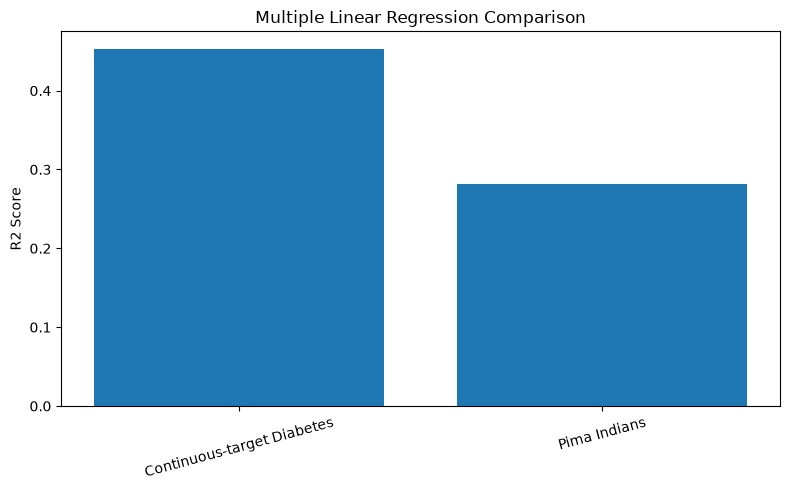

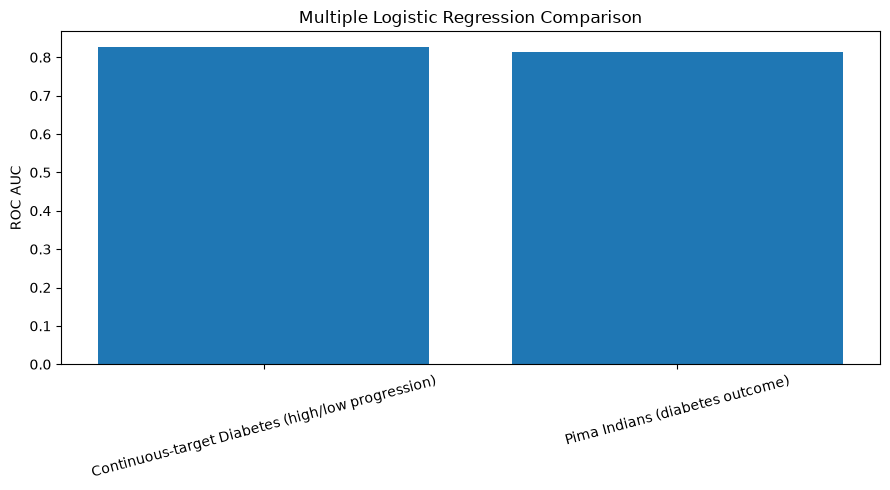

In [12]:
# Plot multiple linear regression R2 scores and logistic regression ROC AUC scores
plt.figure(figsize=(8, 5))
plt.bar(multiple_linear_comparison["Dataset"], multiple_linear_comparison["R2"])
plt.ylabel("R2 Score")
plt.title("Multiple Linear Regression Comparison")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.bar(multiple_logistic_comparison["Dataset"], multiple_logistic_comparison["ROC AUC"])
plt.ylabel("ROC AUC")
plt.title("Multiple Logistic Regression Comparison")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()